# DSCI 552 - Homework 5


Name: Sumi Li
<br>
Github Username: SumiLi-1
<br>
USC ID: 5751493781

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
DATA_DIR = Path.cwd() / 'data'
print('Data directory:', DATA_DIR.resolve())

Data directory: F:\jupyterwork\HW5\data


### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
# Acute Inflammations: 6 个症状特征 + 2 个诊断标签。
cols = ['temperature','nausea','lumbar_pain','urine_pushing','micturition_pains','burning_urethra','bladder_inflammation','nephritis']
acute = pd.read_csv(DATA_DIR / 'diagnosis.data', sep='\t', header=None, names=cols, encoding='utf-16')
# 温度使用逗号作小数点；yes/no 转成 1/0，供 sklearn 使用。
acute['temperature'] = acute['temperature'].str.replace(',', '.', regex=False).astype(float)
for col in cols[1:]:
    # 显式转为 int，避免 sklearn 将 object 标签识别为 unknown。
    acute[col] = acute[col].map({'yes': 1, 'no': 0}).astype(int)
acute_features, acute_targets = cols[:6], cols[6:]
X_acute, y_acute = acute[acute_features], acute[acute_targets]
display(acute.head())
print('X shape:', X_acute.shape, '| y shape:', y_acute.shape)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


X shape: (120, 6) | y shape: (120, 2)


### (b) Build a decision tree

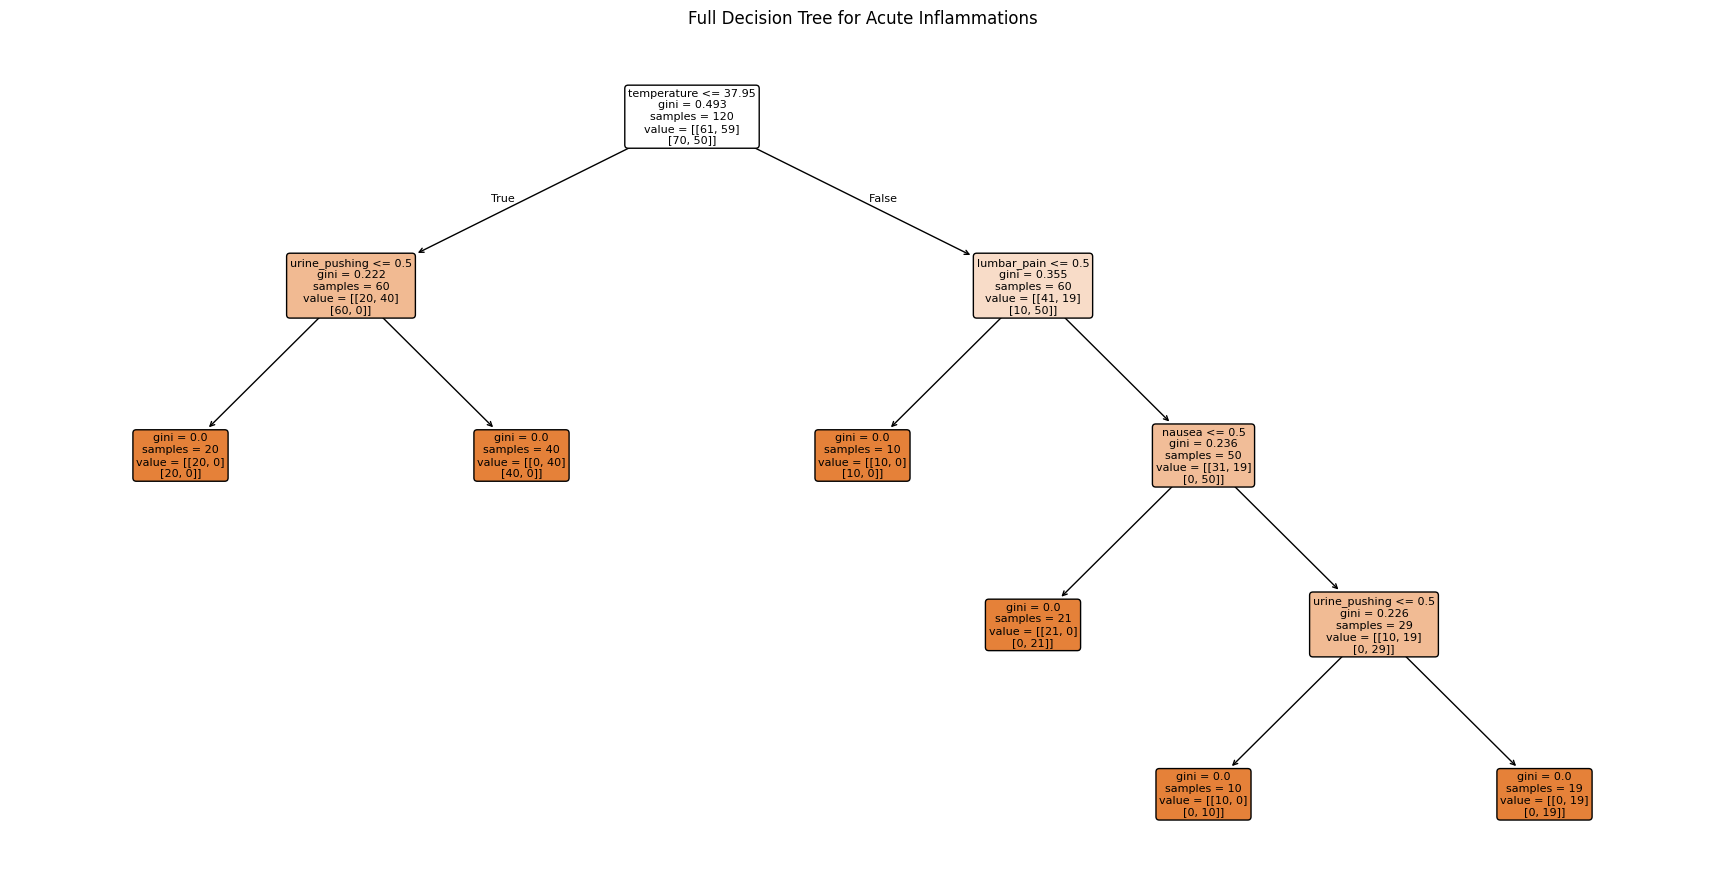

Depth: 4
Leaves: 6
Training exact-match accuracy: 1.0


In [3]:
# 用全体样本训练多输出决策树；每个叶子会同时预测两个诊断。
full_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
full_tree.fit(X_acute, y_acute)
plt.figure(figsize=(22, 11))
plot_tree(full_tree, feature_names=acute_features, filled=True, rounded=True, fontsize=8)
plt.title('Full Decision Tree for Acute Inflammations')
plt.show()
print('Depth:', full_tree.get_depth())
print('Leaves:', full_tree.get_n_leaves())
print('Training exact-match accuracy:', full_tree.score(X_acute, y_acute))


### (c) Convert the decision rules and (d) Prune the tree


Rules from full tree:
IF temperature <= 37.950 AND urine_pushing <= 0.500 THEN bladder_inflammation = 0 AND nephritis = 0
IF temperature <= 37.950 AND urine_pushing > 0.500 THEN bladder_inflammation = 1 AND nephritis = 0
IF temperature > 37.950 AND lumbar_pain <= 0.500 THEN bladder_inflammation = 0 AND nephritis = 0
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea <= 0.500 THEN bladder_inflammation = 0 AND nephritis = 1
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea > 0.500 AND urine_pushing <= 0.500 THEN bladder_inflammation = 0 AND nephritis = 1
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea > 0.500 AND urine_pushing > 0.500 THEN bladder_inflammation = 1 AND nephritis = 1
Best alpha: 0.0
Pruned depth: 4 | leaves: 6
Best CV score: 0.95


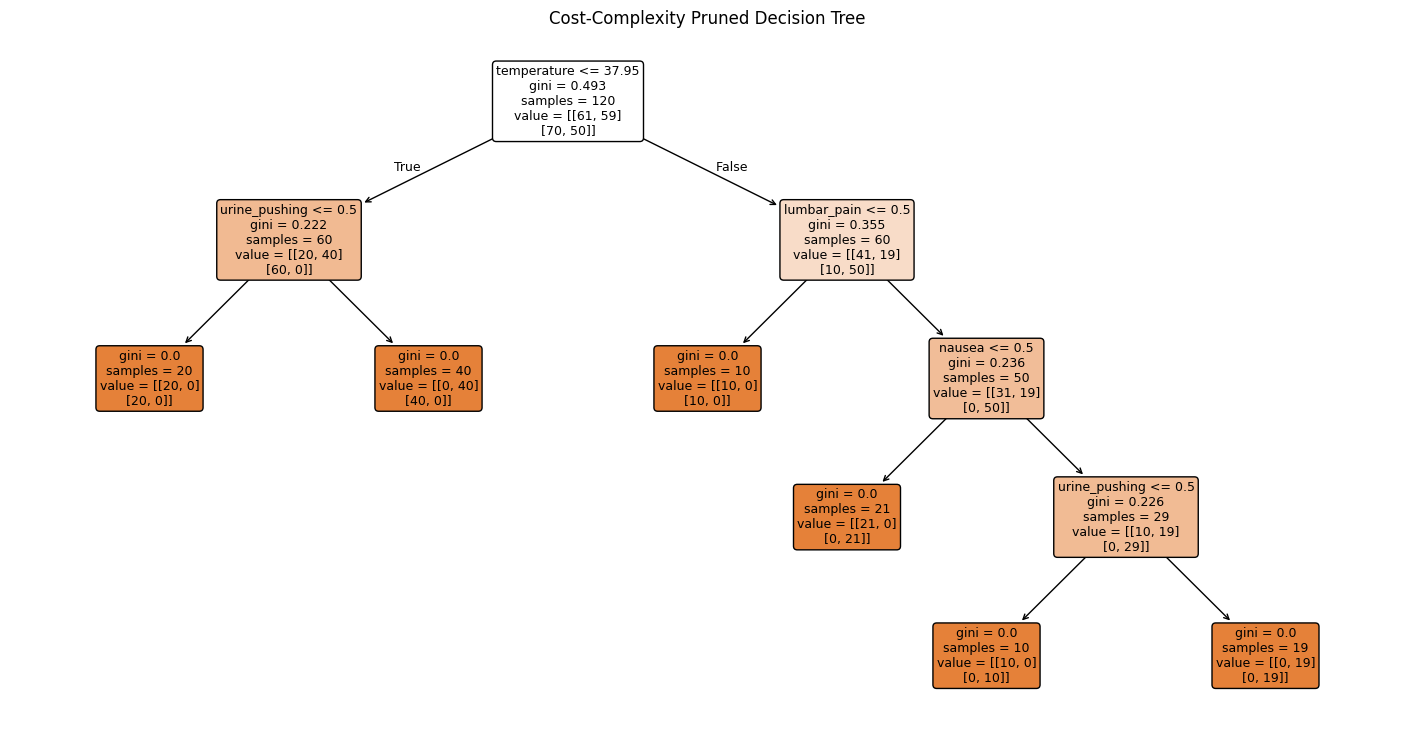

Rules from pruned tree:
IF temperature <= 37.950 AND urine_pushing <= 0.500 THEN bladder_inflammation = 0 AND nephritis = 0
IF temperature <= 37.950 AND urine_pushing > 0.500 THEN bladder_inflammation = 1 AND nephritis = 0
IF temperature > 37.950 AND lumbar_pain <= 0.500 THEN bladder_inflammation = 0 AND nephritis = 0
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea <= 0.500 THEN bladder_inflammation = 0 AND nephritis = 1
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea > 0.500 AND urine_pushing <= 0.500 THEN bladder_inflammation = 0 AND nephritis = 1
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea > 0.500 AND urine_pushing > 0.500 THEN bladder_inflammation = 1 AND nephritis = 1


In [4]:
# (c) 递归走访树，在叶节点把预测写成 IF-THEN 规则。
def print_rules(model, feature_names, target_names):
    tree = model.tree_
    def walk(node, conditions):
        if tree.children_left[node] == tree.children_right[node]:
            prediction = []
            for j, target in enumerate(target_names):
                class_id = np.argmax(tree.value[node, j])
                prediction.append(f'{target} = {model.classes_[j][class_id]}')
            print('IF ' + (' AND '.join(conditions) or 'TRUE') + ' THEN ' + ' AND '.join(prediction))
            return
        feature, threshold = feature_names[tree.feature[node]], tree.threshold[node]
        walk(tree.children_left[node], conditions + [f'{feature} <= {threshold:.3f}'])
        walk(tree.children_right[node], conditions + [f'{feature} > {threshold:.3f}'])
    walk(0, [])

print('Rules from full tree:')
print_rules(full_tree, acute_features, acute_targets)

# (d) Cost-complexity pruning：CV 选 alpha；accuracy 为两个标签均预测正确的比例。
path = full_tree.cost_complexity_pruning_path(X_acute, y_acute)
alphas = np.unique(path.ccp_alphas[:-1])
search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), {'ccp_alpha': alphas}, cv=5, scoring='accuracy')
search.fit(X_acute, y_acute)
pruned_tree = search.best_estimator_
print('Best alpha:', search.best_params_['ccp_alpha'])
print('Pruned depth:', pruned_tree.get_depth(), '| leaves:', pruned_tree.get_n_leaves())
print('Best CV score:', search.best_score_)
plt.figure(figsize=(18, 9))
plot_tree(pruned_tree, feature_names=acute_features, filled=True, rounded=True, fontsize=9)
plt.title('Cost-Complexity Pruned Decision Tree')
plt.show()
print('Rules from pruned tree:')
print_rules(pruned_tree, acute_features, acute_targets)


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [5]:
# 从说明文件自动读取 128 个字段名，避免手写。
names_text = (DATA_DIR / 'communities.names').read_text(encoding='utf-8', errors='ignore')
crime_cols = re.findall(r'^@attribute\s+([^\s]+)', names_text, flags=re.MULTILINE)
assert len(crime_cols) == 128
crime = pd.read_csv(DATA_DIR / 'communities.data', header=None, names=crime_cols, na_values='?')
# 前 1495 行训练，其余测试；不要随机切分。
train_raw, test_raw = crime.iloc[:1495].copy(), crime.iloc[1495:].copy()
print('Original shape:', crime.shape, '| train:', train_raw.shape, '| test:', test_raw.shape)
display(crime.head())


Original shape: (1994, 128) | train: (1495, 128) | test: (499, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values

In [6]:
target = 'ViolentCrimesPerPop'
# 以下五列不具预测意义。
non_predictive = ['state', 'county', 'community', 'communityname', 'fold']
X_train_raw = train_raw.drop(columns=non_predictive + [target])
X_test_raw = test_raw.drop(columns=non_predictive + [target])
y_train, y_test = train_raw[target], test_raw[target]
# 只在训练集 fit 中位数插补器，避免测试集信息泄漏。
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=X_train_raw.columns, index=X_train_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns, index=X_test_raw.index)
print('Predictors:', X_train.shape[1])
print('Missing values after imputation:', X_train.isna().sum().sum())


Predictors: 122
Missing values after imputation: 0


### (c) Plot a correlation matrix

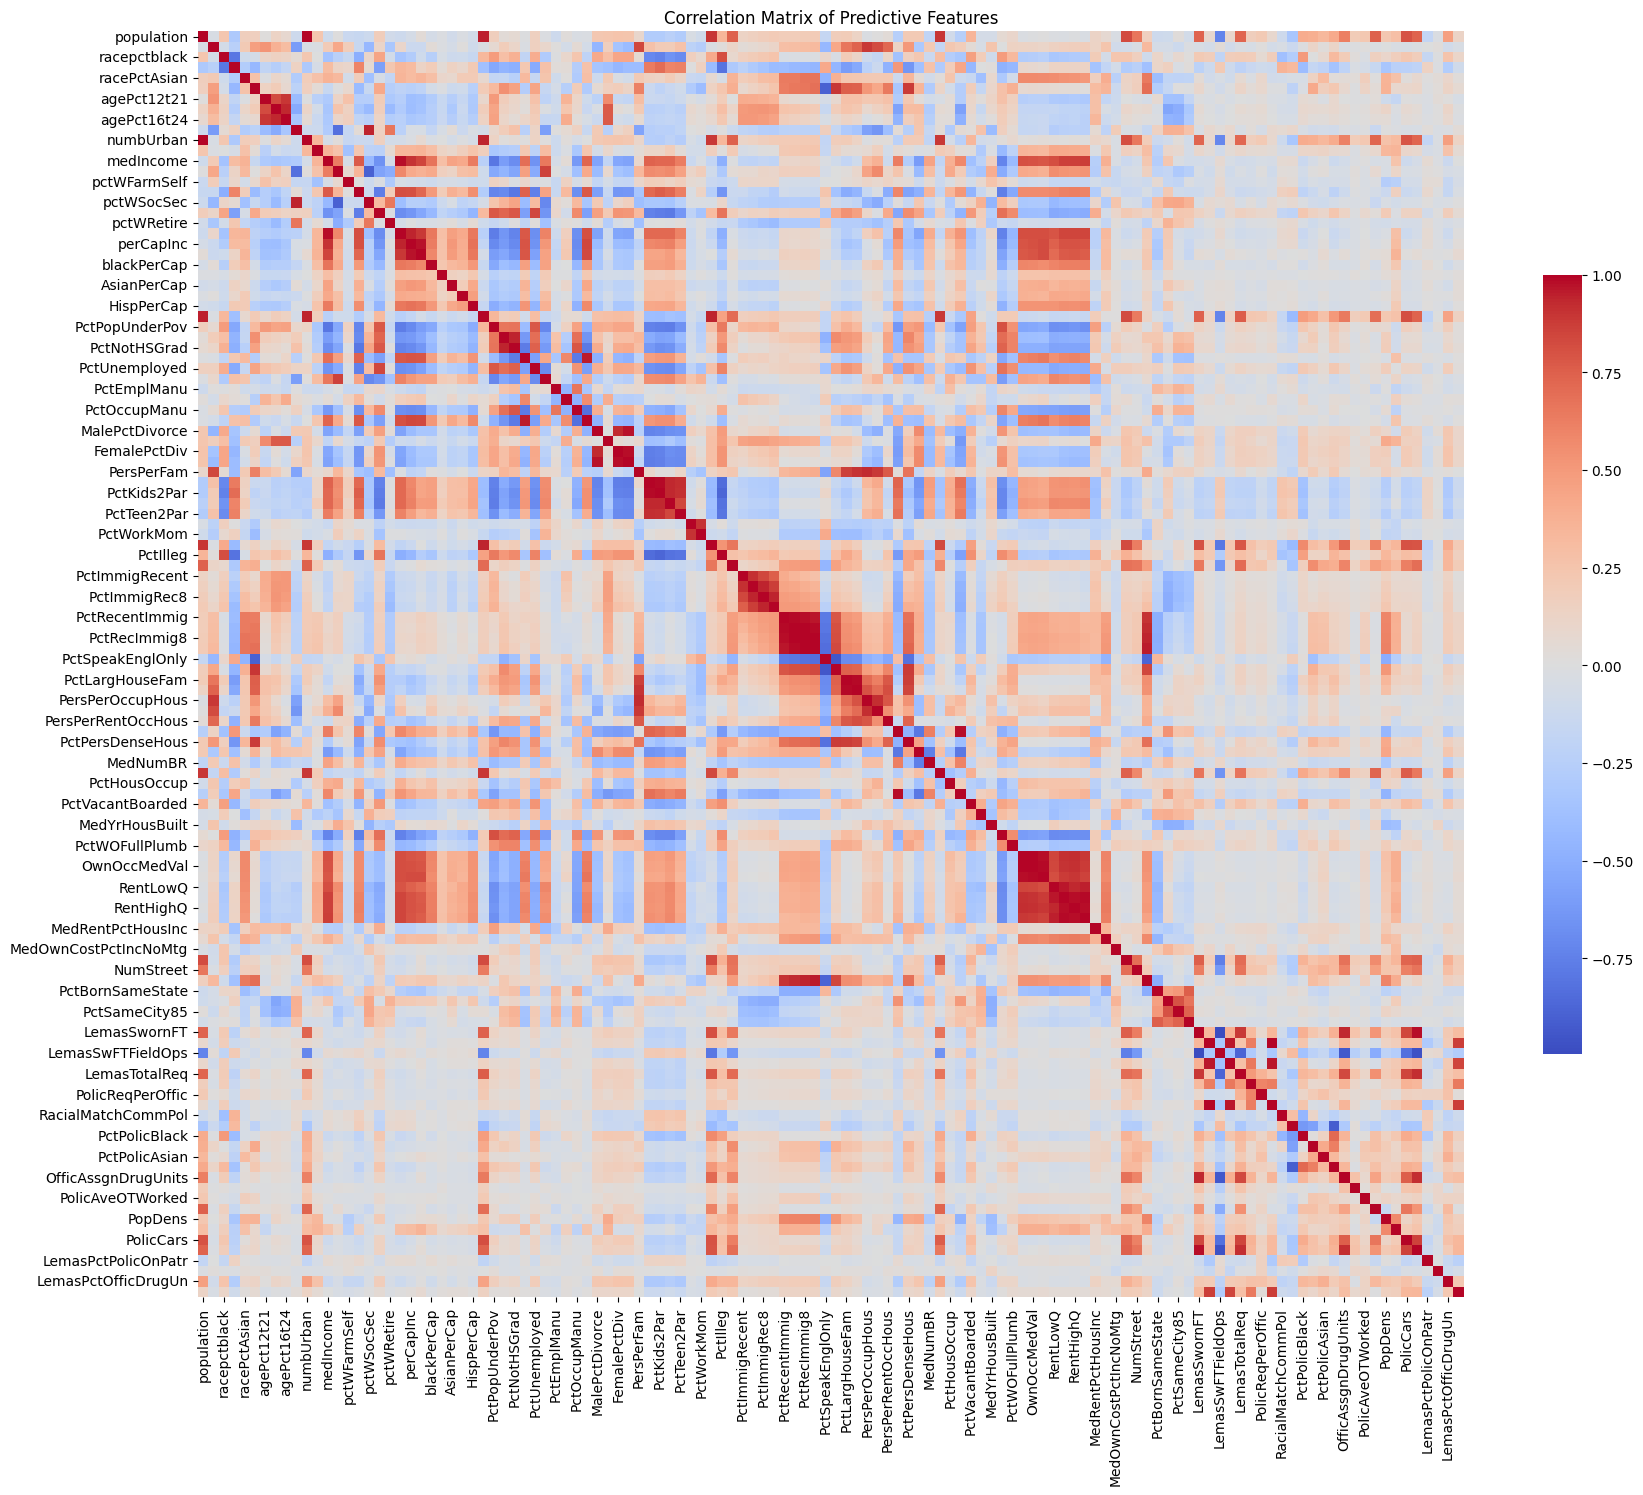

In [7]:
plt.figure(figsize=(18, 15))
sns.heatmap(X_train.corr(), cmap='coolwarm', center=0, square=True, cbar_kws={'shrink': .6})
plt.title('Correlation Matrix of Predictive Features')
plt.tight_layout()
plt.show()


### (d) Calculate the Coefficient of Variation CV

In [8]:
# CV = sample standard deviation / sample mean；均值为 0 的列不能计算 CV。
feature_cv = X_train.std(ddof=1) / X_train.mean().replace(0, np.nan)
cv_table = feature_cv.replace([np.inf, -np.inf], np.nan).dropna().sort_values(ascending=False).rename('CV').to_frame()
display(cv_table.head(15))


,CV
PctPolicAsian,5.527059
NumStreet,4.292923
NumInShelters,3.470952
NumIlleg,3.058964
NumImmig,2.926635
LemasPctOfficDrugUn,2.552946
NumUnderPov,2.342443
LemasSwornFT,2.248042
population,2.241105
numbUrban,2.038461


### (e) Scatter plots and box plots for highest CV features

Top CV features: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'LemasSwornFT', 'population', 'numbUrban', 'HousVacant']


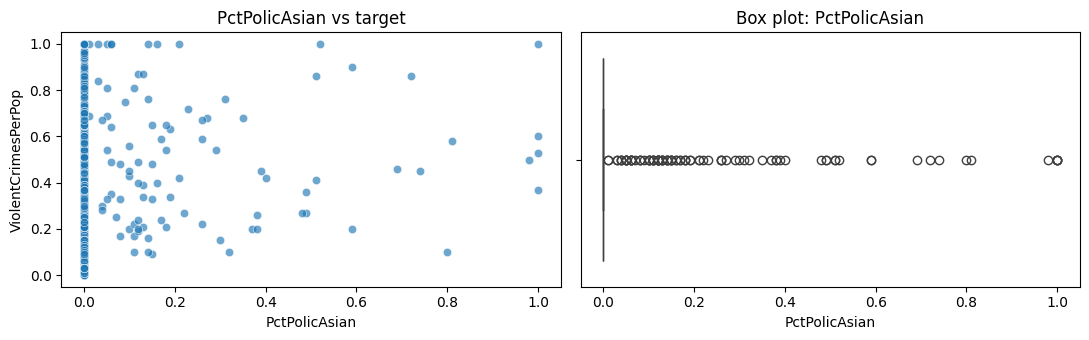

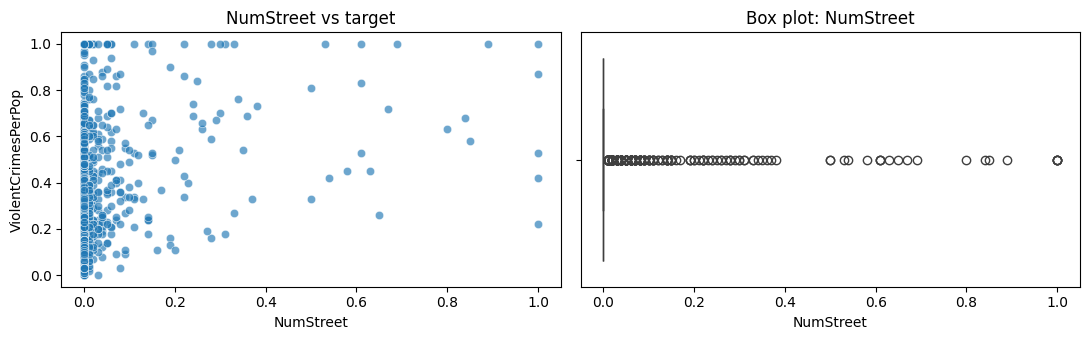

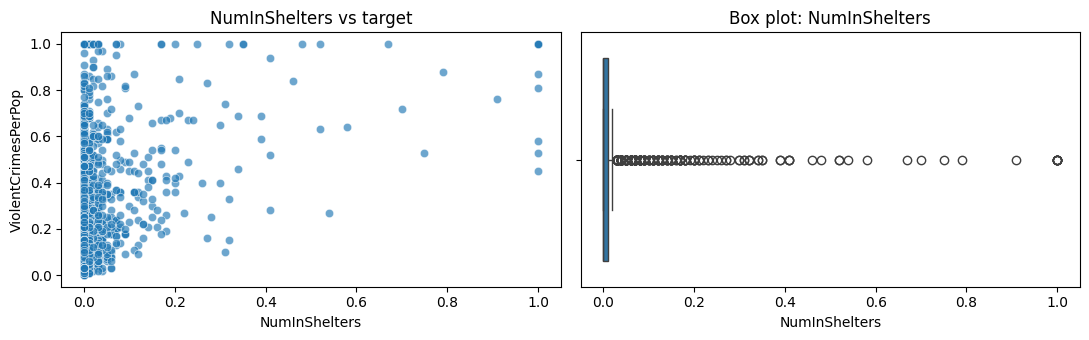

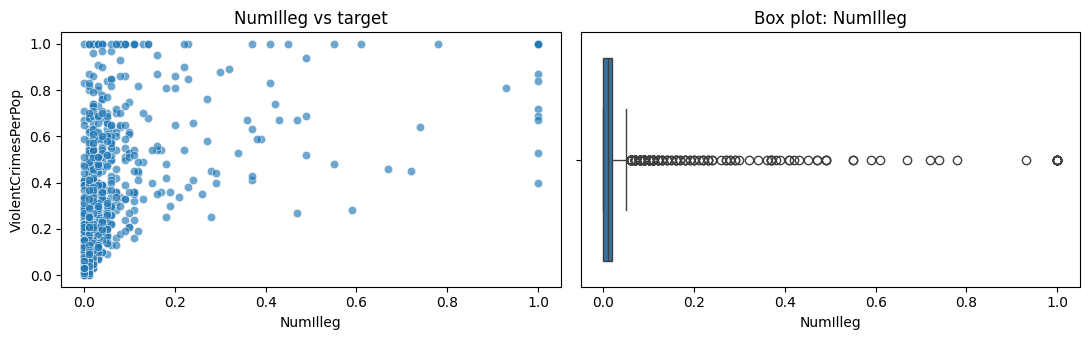

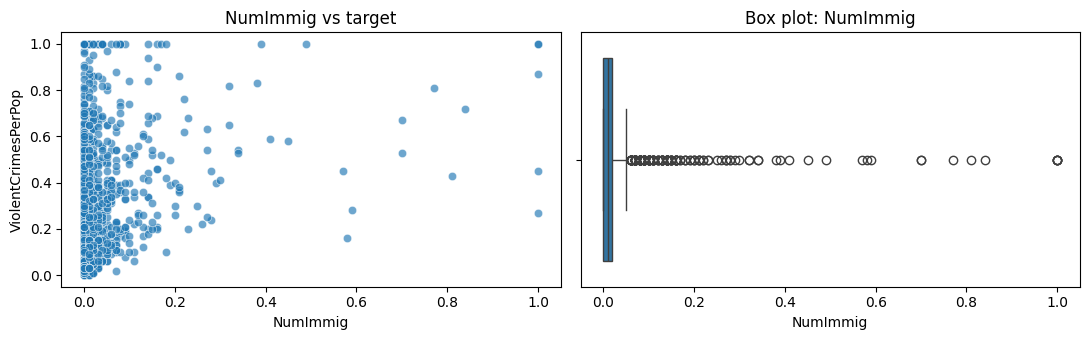

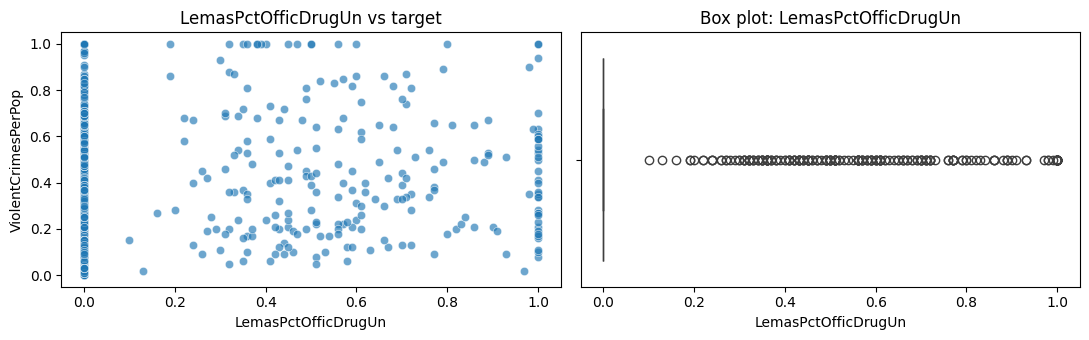

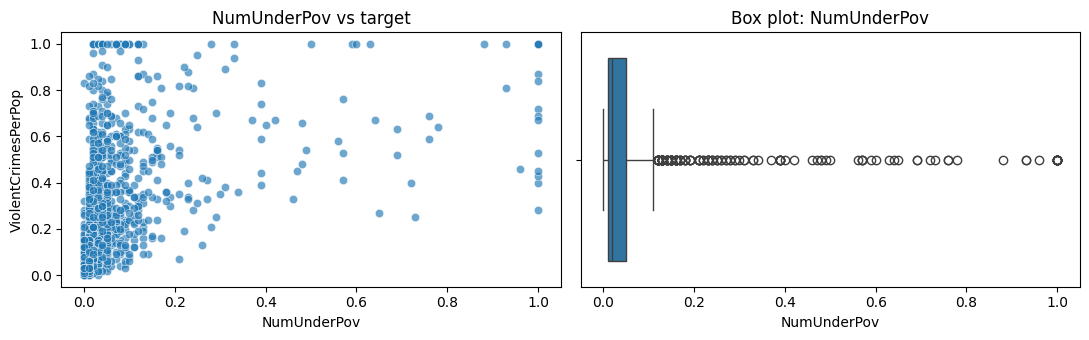

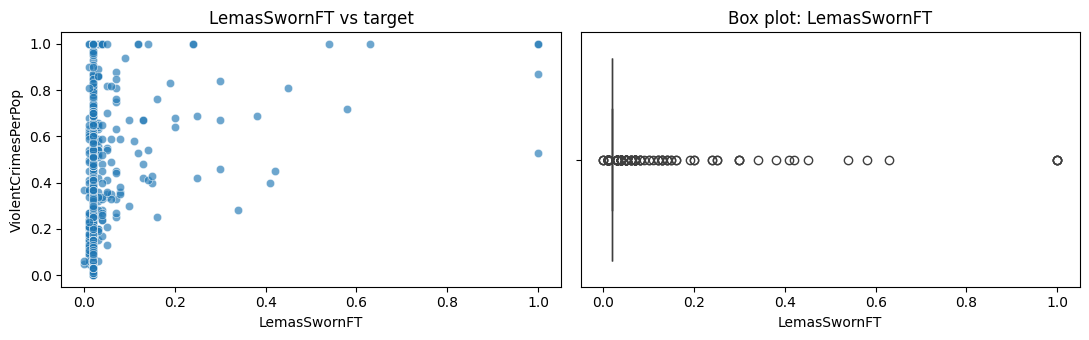

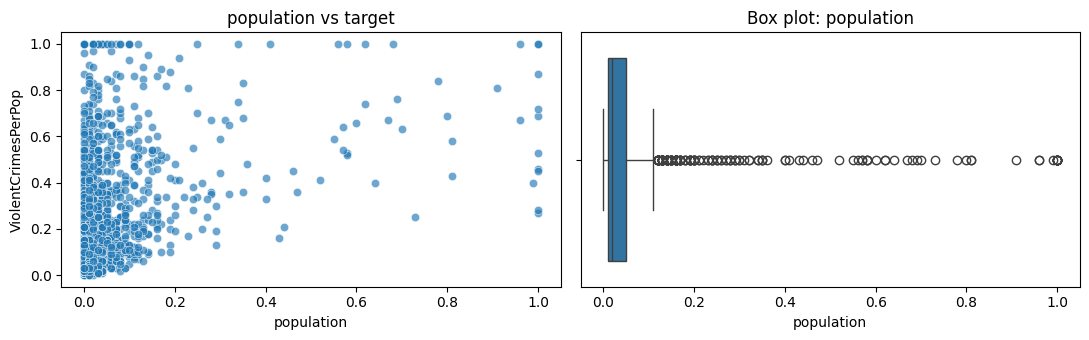

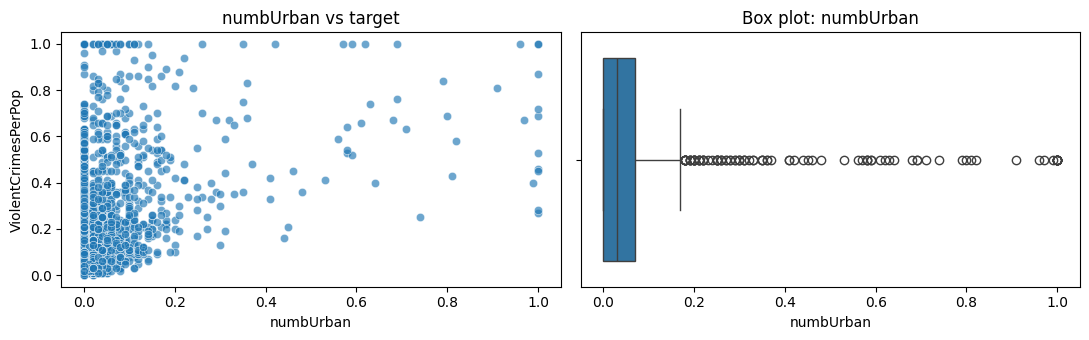

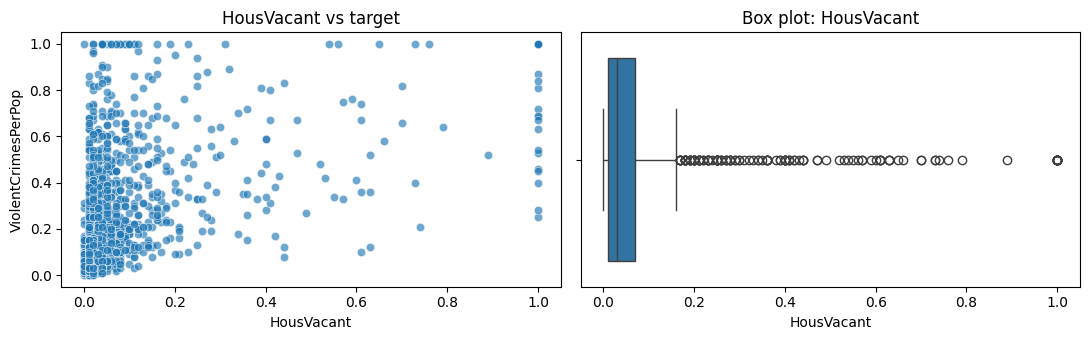

In [9]:
# floor(sqrt(128)) = 11，按题目要求选择 CV 最大的 11 个特征。
top_k = int(np.floor(np.sqrt(128)))
top_features = cv_table.head(top_k).index.tolist()
print('Top CV features:', top_features)
for feature in top_features:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    sns.scatterplot(x=X_train[feature], y=y_train, alpha=.65, ax=ax[0])
    ax[0].set_title(f'{feature} vs target')
    sns.boxplot(x=X_train[feature], ax=ax[1])
    ax[1].set_title(f'Box plot: {feature}')
    plt.tight_layout(); plt.show()


Scatter plots may reveal potential associations or non-linear relationships, but they alone cannot establish statistical significance. Statistical tests or regression analysis are needed to evaluate significance while accounting for other variables.

### (f) Fit a linear model

In [10]:
# 统一以 MSE 作为 test error，便于横向比较模型。
def evaluate(name, model):
    model.fit(X_train, y_train)
    mse = mean_squared_error(y_test, model.predict(X_test))
    print(f'{name} test MSE: {mse:.6f}')
    return model, mse

ols_model, ols_mse = evaluate('OLS', LinearRegression())


OLS test MSE: 0.017966


### (g) Fit a ridge regression model

In [11]:
# Pipeline 确保每一折交叉验证都只用该折训练数据完成标准化。
ridge_model = Pipeline([('scaler', StandardScaler()), ('ridge', RidgeCV(alphas=np.logspace(-4, 4, 60), cv=5))])
ridge_model, ridge_mse = evaluate('Ridge', ridge_model)
print('Selected lambda:', ridge_model.named_steps['ridge'].alpha_)


Ridge test MSE: 0.017412
Selected lambda: 92.49147277217335


### (h) Fit a LASSO model

In [12]:
# 第一版：不额外标准化。
lasso_raw, lasso_raw_mse = evaluate('LASSO without standardization', LassoCV(cv=5, max_iter=50000, random_state=RANDOM_STATE))
# 第二版：标准化版本。
lasso_scaled = Pipeline([('scaler', StandardScaler()), ('lasso', LassoCV(cv=5, max_iter=50000, random_state=RANDOM_STATE))])
lasso_scaled, lasso_scaled_mse = evaluate('LASSO with standardization', lasso_scaled)
selected = X_train.columns[lasso_scaled.named_steps['lasso'].coef_ != 0].tolist()
print('Raw alpha:', lasso_raw.alpha_)
print('Scaled alpha:', lasso_scaled.named_steps['lasso'].alpha_)
print('Selected variables:', selected)
print('Number selected:', len(selected))


LASSO without standardization test MSE: 0.017618
LASSO with standardization test MSE: 0.017682
Raw alpha: 0.00012454087437758504
Scaled alpha: 0.0007630833878262516
Selected variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCost

### (i) Fit a PCR model

In [13]:
# PCR = StandardScaler + PCA + Linear Regression；用 CV 决定主成分数 M。
pcr = Pipeline([('scaler', StandardScaler()), ('pca', PCA()), ('linear', LinearRegression())])
max_m = min(X_train.shape[1], 100)  # 速度与搜索范围的折中
pcr_search = GridSearchCV(pcr, {'pca__n_components': list(range(1, max_m + 1))}, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
pcr_search.fit(X_train, y_train)
pcr_mse = mean_squared_error(y_test, pcr_search.predict(X_test))
print('Best M:', pcr_search.best_params_['pca__n_components'])
print(f'PCR test MSE: {pcr_mse:.6f}')


Best M: 95
PCR test MSE: 0.018296


### (j) Fit a boosting tree

In [14]:
# XGBoost 中的 alpha 是 L1 正则化系数，对应题目中的 α。
from xgboost import XGBRegressor
xgb = XGBRegressor(objective='reg:squarederror', n_estimators=300, max_depth=3, learning_rate=.05, subsample=.8, colsample_bytree=.8, random_state=RANDOM_STATE, n_jobs=-1)
# 题目只要求通过 CV 选择 alpha，其他参数采用简洁的固定配置。
xgb_search = GridSearchCV(xgb, {'alpha': [0, .001, .01, .1, 1, 10]}, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
xgb_search.fit(X_train, y_train)
xgb_mse = mean_squared_error(y_test, xgb_search.predict(X_test))
print('Best alpha:', xgb_search.best_params_['alpha'])
print(f'XGBoost test MSE: {xgb_mse:.6f}')



Best alpha: 1
XGBoost test MSE: 0.015847


## 3. Model Comparison and Discussion

In [15]:
# 汇总所有模型的测试 MSE；MSE 越小，模型在测试集上的预测误差越低。
mse_summary = pd.DataFrame({
    'Model': [
        'OLS',
        'Ridge',
        'LASSO (without standardization)',
        'LASSO (with standardization)',
        'PCR',
        'XGBoost'
    ],
    'Test MSE': [
        ols_mse,
        ridge_mse,
        lasso_raw_mse,
        lasso_scaled_mse,
        pcr_mse,
        xgb_mse
    ]
}).sort_values('Test MSE').reset_index(drop=True)

display(mse_summary.style.format({'Test MSE': '{:.6f}'}))

best_model = mse_summary.loc[0, 'Model']
best_mse = mse_summary.loc[0, 'Test MSE']
print(f'Best model by test MSE: {best_model} ({best_mse:.6f})')
print('Interpretation: A lower test MSE indicates better predictive performance on unseen data.')


,Model,Test MSE
0,XGBoost,0.015847
1,Ridge,0.017412
2,LASSO (without standardization),0.017618
3,LASSO (with standardization),0.017682
4,OLS,0.017966
5,PCR,0.018296


Best model by test MSE: XGBoost (0.015847)
Interpretation: A lower test MSE indicates better predictive performance on unseen data.
